In [1]:
print("Hello, Unsupervised Learning!")

Hello, Unsupervised Learning!


In [2]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns
import plotly
import flask

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Plotly:", plotly.__version__)
print("Flask:", flask.__version__)

Pandas: 3.0.6
NumPy: 2.5.3
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
Seaborn: 0.13.2
Plotly: 7.1.0
Flask: 3.1.3


C:\Users\Harshith\AppData\Local\Temp\ipykernel_33232\3493959889.py:15: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("Flask:", flask.__version__)


In [3]:
import zipfile
import os

zip_path = "archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files = zip_ref.namelist()

print("Files inside archive.zip:")
for file in files:
    print(file)

Files inside archive.zip:
nfhs_district_health_long.csv


In [4]:
import pandas as pd
import zipfile

zip_path = "archive.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    with zip_ref.open("nfhs_district_health_long.csv") as file:
        df = pd.read_csv(file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nColumn names:")
for column in df.columns:
    print(column)

Dataset loaded successfully!
Shape: (52483, 7)

Column names:
state
state_code
district
indicator
survey_round
survey_period
value


In [7]:
print("Number of unique states:", df["state"].nunique())
print("Number of unique districts:", df["district"].nunique())
print("Number of unique indicators:", df["indicator"].nunique())

print("\nSurvey rounds:")
print(df["survey_round"].unique())

print("\nSurvey periods:")
print(df["survey_period"].unique())

Number of unique states: 21
Number of unique districts: 340
Number of unique indicators: 104

Survey rounds:
<StringArray>
['NFHS-5', 'NFHS-4']
Length: 2, dtype: str

Survey periods:
<StringArray>
['2019-2021', '2015-2016']
Length: 2, dtype: str


In [6]:
print(df.columns.tolist())

['state', 'state_code', 'district', 'indicator', 'survey_round', 'survey_period', 'value']


In [8]:
print("ALL 104 INDICATORS:\n")

for i, indicator in enumerate(sorted(df["indicator"].dropna().unique()), start=1):
    print(f"{i}. {indicator}")

ALL 104 INDICATORS:

1. 1. Female population age 6 years and above who ever attended school (%)
2. 10. Households using clean fuel for cooking3 (%)
3. 100. Ever undergone an oral cavity examination for oral cancer (%)
4. 101. Women age 15 years and above who use any kind of tobacco (%)
5. 102. Men age 15 years and above who use any kind of tobacco (%)
6. 103. Women age 15 years and above who consume alcohol (%)
7. 104. Men age 15 years and above who consume alcohol (%)
8. 11. Households using iodized salt (%)
9. 12. Households with any usual member covered under a health insurance/financing scheme (%)
10. 13. Children age 5 years who attended pre-primary school during the school year 2019-20 (%)
11. 14. Women who are literate4 (%)
12. 15. Women with 10 or more years of schooling (%)
13. 16. Women age 20-24 years married before age 18 years (%)
14. 17. Births in the 5 years preceding the survey that are third or higher order (%)
15. 18. Women age 15-19 years who were already mothers or 

In [9]:
indicators = df["indicator"].dropna().unique()

print(f"Total indicators: {len(indicators)}")

for i, indicator in enumerate(indicators, start=1):
    print(f"{i}. {indicator}")

Total indicators: 104
1. 1. Female population age 6 years and above who ever attended school (%)
2. 2. Population below age 15 years (%)
3. 3. Sex ratio of the total population (females per 1,000 males)
4. 4. Sex ratio at birth for children born in the last five years (females per 1,000 males)
5. 5. Children under age 5 years whose birth was registered with the civil authority (%)
6. 6. Deaths in the last 3 years registered with the civil authority (%)
7. 7. Population living in households with electricity (%)
8. 8. Population living in households with an improved drinking-water source1 (%)
9. 9. Population living in households that use an improved sanitation facility2 (%)
10. 10. Households using clean fuel for cooking3 (%)
11. 11. Households using iodized salt (%)
12. 12. Households with any usual member covered under a health insurance/financing scheme (%)
13. 13. Children age 5 years who attended pre-primary school during the school year 2019-20 (%)
14. 14. Women who are literate4 

In [10]:
indicators = df["indicator"].dropna().unique()

for start in range(0, len(indicators), 25):
    end = min(start + 25, len(indicators))
    
    print(f"\n========== INDICATORS {start + 1}–{end} ==========\n")
    
    for i in range(start, end):
        print(f"{i + 1}. {indicators[i]}")


========== INDICATORS 1–25 ==========

1. 1. Female population age 6 years and above who ever attended school (%)
2. 2. Population below age 15 years (%)
3. 3. Sex ratio of the total population (females per 1,000 males)
4. 4. Sex ratio at birth for children born in the last five years (females per 1,000 males)
5. 5. Children under age 5 years whose birth was registered with the civil authority (%)
6. 6. Deaths in the last 3 years registered with the civil authority (%)
7. 7. Population living in households with electricity (%)
8. 8. Population living in households with an improved drinking-water source1 (%)
9. 9. Population living in households that use an improved sanitation facility2 (%)
10. 10. Households using clean fuel for cooking3 (%)
11. 11. Households using iodized salt (%)
12. 12. Households with any usual member covered under a health insurance/financing scheme (%)
13. 13. Children age 5 years who attended pre-primary school during the school year 2019-20 (%)
14. 14. Women 

In [11]:
print("Survey rounds:")
print(df["survey_round"].value_counts(dropna=False))

print("\nSurvey periods:")
print(df["survey_period"].value_counts(dropna=False))

Survey rounds:
survey_round
NFHS-5    33446
NFHS-4    19037
Name: count, dtype: int64

Survey periods:
survey_period
2019-2021    33446
2015-2016    19037
Name: count, dtype: int64


In [12]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
state            0
state_code       0
district         0
indicator        0
survey_round     0
survey_period    0
value            0
dtype: int64


In [13]:
print("Data types:")
print(df.dtypes)

Data types:
state                str
state_code           str
district             str
indicator            str
survey_round         str
survey_period        str
value            float64
dtype: object


In [14]:
indicator_coverage = (
    nfhs5.groupby("indicator")["district"]
    .nunique()
    .sort_values(ascending=False)
)

print("District coverage for each NFHS-5 indicator:\n")
print(indicator_coverage.to_string())

NameError: name 'nfhs5' is not defined

In [15]:
# Select only the NFHS-5 records
nfhs5 = df[df["survey_round"] == "NFHS-5"].copy()

# Basic NFHS-5 information
print("NFHS-5 shape:", nfhs5.shape)
print("NFHS-5 districts:", nfhs5["district"].nunique())
print("NFHS-5 indicators:", nfhs5["indicator"].nunique())

# Records per district
print("\nRecords per district:")
print(nfhs5.groupby("district").size().describe())

# Records per indicator
print("\nRecords per indicator:")
print(nfhs5.groupby("indicator").size().describe())

# District coverage for every indicator
indicator_coverage = (
    nfhs5.groupby("indicator")["district"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nDistrict coverage for each NFHS-5 indicator:")
print(indicator_coverage.to_string())

NFHS-5 shape: (33446, 7)
NFHS-5 districts: 340
NFHS-5 indicators: 104

Records per district:
count    340.000000
mean      98.370588
std        6.586682
min       83.000000
25%       96.000000
50%       98.000000
75%      100.000000
max      203.000000
dtype: float64

Records per indicator:
count    104.000000
mean     321.596154
std       62.817121
min       28.000000
25%      341.000000
50%      341.000000
75%      341.000000
max      341.000000
dtype: float64

District coverage for each NFHS-5 indicator:
indicator
1. Female population age 6 years and above who ever attended school (%)                                                                340
10. Households using clean fuel for cooking3 (%)                                                                                       340
100. Ever undergone an oral cavity examination for oral cancer (%)                                                                     340
102. Men age 15 years and above who use any kind of tobacco 

In [16]:
# Calculate how many district records each indicator has
indicator_coverage = (
    nfhs5.groupby("indicator")["district"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 20 indicators by district coverage:\n")
print(indicator_coverage.head(20).to_string())

print("\nBottom 20 indicators by district coverage:\n")
print(indicator_coverage.tail(20).to_string())

Top 20 indicators by district coverage:

indicator
1. Female population age 6 years and above who ever attended school (%)                                340
10. Households using clean fuel for cooking3 (%)                                                       340
100. Ever undergone an oral cavity examination for oral cancer (%)                                     340
102. Men age 15 years and above who use any kind of tobacco (%)                                        340
104. Men age 15 years and above who consume alcohol (%)                                                340
103. Women age 15 years and above who consume alcohol (%)                                              340
11. Households using iodized salt (%)                                                                  340
12. Households with any usual member covered under a health insurance/financing scheme (%)             340
27. Injectables (%)                                                                          

In [17]:
duplicates = nfhs5.duplicated(
    subset=["state", "district", "indicator", "survey_round"]
)

print("Duplicate district-indicator records:", duplicates.sum())

Duplicate district-indicator records: 0


In [18]:
# Create a clean coverage table
indicator_coverage = (
    nfhs5.groupby("indicator")["district"]
    .nunique()
    .reset_index(name="district_count")
    .sort_values("district_count", ascending=False)
)

print("Total indicators:", len(indicator_coverage))
print("Maximum district coverage:", indicator_coverage["district_count"].max())
print("Minimum district coverage:", indicator_coverage["district_count"].min())

print("\nCoverage distribution:")
print(indicator_coverage["district_count"].value_counts().sort_index())

print("\nIndicators with less than 300 districts:")
display(
    indicator_coverage[indicator_coverage["district_count"] < 300]
)

Total indicators: 104
Maximum district coverage: 340
Minimum district coverage: 28

Coverage distribution:
district_count
28      1
30      1
110     3
122     1
173     1
267     1
268     1
270     1
325     1
330     2
332     8
339     4
340    79
Name: count, dtype: int64

Indicators with less than 300 districts:


,indicator,district_count
86,83. Pregnant women age 15-49 years who are ana...,270
67,66. Children with fever or symptoms of ARI in ...,268
46,47. Births in a private health facility that w...,267
69,68. Children under age 6 months exclusively br...,173
39,40. Children born at home who were taken to a ...,122
63,62. Children with diarrhoea in the 2 weeks pre...,110
65,64. Children with diarrhoea in the 2 weeks pre...,110
64,63. Children with diarrhoea in the 2 weeks pre...,110
70,69. Children age 6-8 months receiving solid or...,30
73,71. Non-breastfeeding children age 6-23 months...,28


In [19]:
high_coverage = indicator_coverage[
    indicator_coverage["district_count"] >= 330
].copy()

print("Indicators with >= 330 district coverage:")
print("Count:", len(high_coverage))

display(high_coverage)

Indicators with >= 330 district coverage:
Count: 93


,indicator,district_count
0,1. Female population age 6 years and above who...,340
1,10. Households using clean fuel for cooking3 (%),340
2,100. Ever undergone an oral cavity examination...,340
4,102. Men age 15 years and above who use any ki...,340
6,104. Men age 15 years and above who consume al...,340
...,...,...
56,56. Children age 12-23 months who have receive...,332
53,53. Children age 12-23 months who have receive...,332
57,57. Children age 12-23 months who have receive...,332
61,60. Children age 12-23 months who received mos...,330


In [20]:
indicator_coverage.to_csv(
    "indicator_coverage.csv",
    index=False
)

print("Saved: indicator_coverage.csv")

Saved: indicator_coverage.csv


In [21]:
low_coverage = indicator_coverage[
    indicator_coverage["district_count"] < 330
].copy()

print("Indicators with < 330 district coverage:")
display(low_coverage)

Indicators with < 330 district coverage:


,indicator,district_count
50,50. Children age 12-23 months fully vaccinated...,325
86,83. Pregnant women age 15-49 years who are ana...,270
67,66. Children with fever or symptoms of ARI in ...,268
46,47. Births in a private health facility that w...,267
69,68. Children under age 6 months exclusively br...,173
39,40. Children born at home who were taken to a ...,122
63,62. Children with diarrhoea in the 2 weeks pre...,110
65,64. Children with diarrhoea in the 2 weeks pre...,110
64,63. Children with diarrhoea in the 2 weeks pre...,110
70,69. Children age 6-8 months receiving solid or...,30


In [22]:
kmeans.fit(X_scaled)

NameError: name 'kmeans' is not defined

In [23]:
high_coverage = indicator_coverage[
    indicator_coverage["district_count"] >= 330
].copy()

print("Indicators with >= 330 district coverage:")
print("Count:", len(high_coverage))

display(high_coverage)

Indicators with >= 330 district coverage:
Count: 93


,indicator,district_count
0,1. Female population age 6 years and above who...,340
1,10. Households using clean fuel for cooking3 (%),340
2,100. Ever undergone an oral cavity examination...,340
4,102. Men age 15 years and above who use any ki...,340
6,104. Men age 15 years and above who consume al...,340
...,...,...
56,56. Children age 12-23 months who have receive...,332
53,53. Children age 12-23 months who have receive...,332
57,57. Children age 12-23 months who have receive...,332
61,60. Children age 12-23 months who received mos...,330


In [24]:
high_indicators = high_coverage["indicator"].tolist()

for start in range(0, len(high_indicators), 20):
    end = min(start + 20, len(high_indicators))

    print(f"\n========== INDICATORS {start + 1}–{end} ==========\n")

    for i in range(start, end):
        print(f"{i + 1}. {high_indicators[i]}")



========== INDICATORS 1–20 ==========

1. 1. Female population age 6 years and above who ever attended school (%)
2. 10. Households using clean fuel for cooking3 (%)
3. 100. Ever undergone an oral cavity examination for oral cancer (%)
4. 102. Men age 15 years and above who use any kind of tobacco (%)
5. 104. Men age 15 years and above who consume alcohol (%)
6. 103. Women age 15 years and above who consume alcohol (%)
7. 11. Households using iodized salt (%)
8. 12. Households with any usual member covered under a health insurance/financing scheme (%)
9. 27. Injectables (%)
10. 13. Children age 5 years who attended pre-primary school during the school year 2019-20 (%)
11. 14. Women who are literate4 (%)
12. 15. Women with 10 or more years of schooling (%)
13. 16. Women age 20-24 years married before age 18 years (%)
14. 17. Births in the 5 years preceding the survey that are third or higher order (%)
15. 18. Women age 15-19 years who were already mothers or pregnant at the time of the

In [25]:
# Save all 93 high-coverage indicators to a text file

high_indicators = high_coverage["indicator"].tolist()

with open("high_coverage_indicators.txt", "w", encoding="utf-8") as f:
    for i, indicator in enumerate(high_indicators, start=1):
        f.write(f"{i}. {indicator}\n")

print(f"Saved {len(high_indicators)} indicators to high_coverage_indicators.txt")

Saved 93 indicators to high_coverage_indicators.txt


In [26]:
# ============================================================
# FINAL CORE FEATURES FOR HEALTHCARE ACCESS CLUSTERING
# ============================================================

selected_indicators = [
    "12. Households with any usual member covered under a health insurance/financing scheme (%)",
    "30. Health worker ever talked to female non-users about family planning (%)",
    "32. Mothers who had an antenatal check-up in the first trimester (%)",
    "33. Mothers who had at least 4 antenatal care visits (%)",
    "34. Mothers whose last birth was protected against neonatal tetanus9 (%)",
    "35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)",
    "42. Institutional births (%)",
    "45. Births attended by skilled health personnel10 (%)",
    "43. Institutional births in public facility (%)",
    "38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%)",
    "58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%)",
    "54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)",
    "53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)",
    "8. Population living in households with an improved drinking-water source1 (%)",
    "9. Population living in households that use an improved sanitation facility2 (%)"
]

print("Number of selected indicators:", len(selected_indicators))

print("\nSelected indicators:")
for i, indicator in enumerate(selected_indicators, start=1):
    print(f"{i}. {indicator}")

Number of selected indicators: 15

Selected indicators:
1. 12. Households with any usual member covered under a health insurance/financing scheme (%)
2. 30. Health worker ever talked to female non-users about family planning (%)
3. 32. Mothers who had an antenatal check-up in the first trimester (%)
4. 33. Mothers who had at least 4 antenatal care visits (%)
5. 34. Mothers whose last birth was protected against neonatal tetanus9 (%)
6. 35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)
7. 42. Institutional births (%)
8. 45. Births attended by skilled health personnel10 (%)
9. 43. Institutional births in public facility (%)
10. 38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%)
11. 58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%)
12. 54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)
13

In [27]:
# Check that every selected indicator exists in NFHS-5

missing_features = [
    indicator for indicator in selected_indicators
    if indicator not in nfhs5["indicator"].unique()
]

print("Selected indicators:", len(selected_indicators))
print("Missing indicators:", len(missing_features))

if missing_features:
    print("\nMissing features:")
    for indicator in missing_features:
        print(indicator)
else:
    print("\nSUCCESS: All 15 selected indicators are present in the dataset.")

Selected indicators: 15
Missing indicators: 0

SUCCESS: All 15 selected indicators are present in the dataset.


In [28]:
# ============================================================
# CREATE DISTRICT-LEVEL FEATURE MATRIX
# ============================================================

# Keep only the selected 15 indicators
selected_data = nfhs5[
    nfhs5["indicator"].isin(selected_indicators)
].copy()

print("Selected records:", selected_data.shape)
print("Districts:", selected_data["district"].nunique())
print("Indicators:", selected_data["indicator"].nunique())

Selected records: (5099, 7)
Districts: 340
Indicators: 15


In [29]:
district_features = selected_data.pivot(
    index="district",
    columns="indicator",
    values="value"
)

ValueError: Index contains duplicate entries, cannot reshape

In [30]:
# ============================================================
# CONVERT LONG FORMAT → DISTRICT-LEVEL WIDE FORMAT
# ============================================================

district_features = selected_data.pivot(
    index="district",
    columns="indicator",
    values="value"
)

print("District-level feature matrix shape:", district_features.shape)

print("\nMissing values by feature:")
print(district_features.isnull().sum())

print("\nTotal missing values:",
      district_features.isnull().sum().sum())

ValueError: Index contains duplicate entries, cannot reshape

In [31]:
index="district"

In [32]:
["state", "district", "indicator", "survey_round"]

['state', 'district', 'indicator', 'survey_round']

In [33]:
# ============================================================
# CONVERT LONG FORMAT → DISTRICT-LEVEL WIDE FORMAT
# Use state + district to uniquely identify each district
# ============================================================

district_features = selected_data.pivot(
    index=["state_code", "state", "district"],
    columns="indicator",
    values="value"
)

# Remove the column index name
district_features.columns.name = None

print("District-level feature matrix shape:", district_features.shape)

print("\nMissing values by feature:")
print(district_features.isnull().sum())

print("\nTotal missing values:",
      district_features.isnull().sum().sum())

District-level feature matrix shape: (341, 15)

Missing values by feature:
12. Households with any usual member covered under a health insurance/financing scheme (%)                                          0
30. Health worker ever talked to female non-users about family planning (%)                                                         0
32. Mothers who had an antenatal check-up in the first trimester (%)                                                                0
33. Mothers who had at least 4 antenatal care visits (%)                                                                            0
34. Mothers whose last birth was protected against neonatal tetanus9 (%)                                                            0
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)                                           0
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of deliv

In [34]:
# ============================================================
# FIND DISTRICTS WITH MISSING VALUES
# ============================================================

missing_rows = district_features[
    district_features.isnull().any(axis=1)
]

print("Number of districts with missing values:",
      len(missing_rows))

print("\nDistricts with missing values:")
display(missing_rows)

Number of districts with missing values: 8

Districts with missing values:


12. Households with any usual member covered under a health insurance/financing scheme (%)  \
state_code state                      district                                                                                                             
AN         Andaman and Nicobar Island North & Middle Andaman                                                2.1                                            
GA         Goa                        South Goa                                                            67.7                                            
KL         Kerala                     Kottayam                                                             53.2                                            
                                      Pathanamthitta                                                       50.1                                            
                                      Thrissur                                                             48.7                                            
MH         Maharashtra                Mumbai                                                               30.7                                            
                                      Mumbai Suburban                                                      20.2                                            
SK         Sikkim                     East District                                                        29.9                                            

                                                              30. Health worker ever talked to female non-users about family planning (%)  \
state_code state                      district                                                                                              
AN         Andaman and Nicobar Island North & Middle Andaman                                               23.2                             
GA         Goa                        South Goa                                                            19.7                             
KL         Kerala                     Kottayam                                                             17.5                             
                                      Pathanamthitta                                                       16.2                             
                                      Thrissur                                                             10.1                             
MH         Maharashtra                Mumbai                                                               19.2                             
                                      Mumbai Suburban                                                      20.4                             
SK         Sikkim                     East District                                                        17.0                             

                                                              32. Mothers who had an antenatal check-up in the first trimester (%)  \
state_code state                      district                                                                                       
AN         Andaman and Nicobar Island North & Middle Andaman                                               74.5                      
GA         Goa                        South Goa                                                            62.7                      
KL         Kerala                     Kottayam                                                             81.6                      
                                      Pathanamthitta                                                       92.9                      
                                      Thrissur                                                             97.1                      
MH         Maharashtra                Mumbai                                                               86.2                      
                  

In [35]:
# ============================================================
# SHOW MISSING-VALUE COUNT FOR EACH DISTRICT
# ============================================================

missing_count = district_features.isnull().sum(axis=1)

print("Missing values per district:")
print(missing_count[missing_count > 0])

Missing values per district:
state_code  state                       district              
AN          Andaman and Nicobar Island  North & Middle Andaman    2
GA          Goa                         South Goa                 2
KL          Kerala                      Kottayam                  2
                                        Pathanamthitta            2
                                        Thrissur                  2
MH          Maharashtra                 Mumbai                    2
                                        Mumbai Suburban           2
SK          Sikkim                      East District             2
dtype: int64


In [36]:
# ============================================================
# IDENTIFY EXACT MISSING DISTRICT-INDICATOR COMBINATIONS
# ============================================================

for index, row in district_features.iterrows():
    missing_indicators = row[row.isnull()].index.tolist()

    if missing_indicators:
        print("\nState/District:", index)
        print("Missing indicators:")

        for indicator in missing_indicators:
            print(" -", indicator)


State/District: ('AN', 'Andaman and Nicobar Island', 'North & Middle Andaman')
Missing indicators:
 - 53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)
 - 54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)

State/District: ('GA', 'Goa', 'South Goa')
Missing indicators:
 - 53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)
 - 54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)

State/District: ('KL', 'Kerala', 'Kottayam')
Missing indicators:
 - 53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)
 - 54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)

State/District: ('KL', 'Kerala', 'Pathanamthitta')
Missing indicators:
 - 53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)
 - 54. Children age 12-23 months

In [37]:
district_features.fillna(0)

12. Households with any usual member covered under a health insurance/financing scheme (%)  \
state_code state                      district                                                                                                                 
AN         Andaman and Nicobar Island Nicobar                                                                   2.7                                            
                                      North & Middle Andaman                                                    2.1                                            
                                      South Andaman                                                             1.2                                            
AP         Andhra Pradesh             Anantapur                                                                73.2                                            
                                      Chittoor                                                                 70.7                                            
...                                                                                                             ...                                            
WB         West Bengal                Purba Barddhaman                                                         37.2                                            
                                      Purba Medinipur                                                          21.5                                            
                                      Puruliya                                                                 35.6                                            
                                      South Twenty Four Parganas                                               36.7                                            
                                      Uttar Dinajpur                                                           21.0                                            

                                                                  30. Health worker ever talked to female non-users about family planning (%)  \
state_code state                      district                                                                                                  
AN         Andaman and Nicobar Island Nicobar                                                                  40.4                             
                                      North & Middle Andaman                                                   23.2                             
                                      South Andaman                                                            31.2                             
AP         Andhra Pradesh             Anantapur                                                                21.9                             
                                      Chittoor                                                                 21.3                             
...                                                                                                             ...                             
WB         West Bengal                Purba Barddhaman                                                         16.0                             
                                      Purba Medinipur                                                          20.6                             
                                      Puruliya                                                                 21.2                             
                                      South Twenty Four Parganas                                               17.7                             
                                      Uttar Dinajpur                                                           10.3                             

                                                                  32. Mothers who had an antenatal 

In [38]:
# ============================================================
# VERIFY THE ORIGINAL VALUES FOR THE TWO MISSING INDICATORS
# ============================================================

vaccination_indicators = [
    "53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)",
    "54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)"
]

problem_districts = [
    ("AN", "North & Middle Andaman"),
    ("GA", "South Goa"),
    ("KL", "Kottayam"),
    ("KL", "Pathanamthitta"),
    ("KL", "Thrissur"),
    ("MH", "Mumbai"),
    ("MH", "Mumbai Suburban"),
    ("SK", "East District")
]

verification = nfhs5[
    nfhs5["indicator"].isin(vaccination_indicators)
].copy()

verification = verification[
    verification.apply(
        lambda row: (row["state_code"], row["district"]) in problem_districts,
        axis=1
    )
]

print("Original NFHS-5 records:")
display(
    verification[
        ["state_code", "state", "district",
         "indicator", "value"]
    ].sort_values(
        ["state_code", "district", "indicator"]
    )
)

Original NFHS-5 records:


,state_code,state,district,indicator,value


In [39]:
# ============================================================
# MEDIAN IMPUTATION FOR THE TWO MISSING INDICATORS
# ============================================================

district_features_imputed = district_features.copy()

for indicator in vaccination_indicators:
    median_value = district_features_imputed[indicator].median()

    print(f"\n{indicator}")
    print(f"Median used for imputation: {median_value:.2f}")

    district_features_imputed[indicator] = (
        district_features_imputed[indicator]
        .fillna(median_value)
    )

print("\nRemaining missing values:",
      district_features_imputed.isnull().sum().sum())


53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)
Median used for imputation: 89.00

54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)
Median used for imputation: 89.40

Remaining missing values: 0


In [40]:
# ============================================================
# SAVE CLEANED DISTRICT-LEVEL DATASET
# ============================================================

district_features_imputed.to_csv(
    "district_features_cleaned.csv"
)

print("Saved: district_features_cleaned.csv")
print("Shape:", district_features_imputed.shape)

Saved: district_features_cleaned.csv
Shape: (341, 15)


In [41]:
# ============================================================
# CHECK FEATURE STATISTICS BEFORE SCALING
# ============================================================

print("Feature statistics before scaling:\n")

display(
    district_features_imputed.describe().T[
        ["min", "mean", "50%", "max", "std"]
    ]
)

Feature statistics before scaling:



,min,mean,50%,max,std
12. Households with any usual member covered under a health insurance/financing scheme (%),1.2,36.740762,33.9,79.5,20.754196
30. Health worker ever talked to female non-users about family planning (%),2.0,22.087683,19.7,64.2,11.670141
32. Mothers who had an antenatal check-up in the first trimester (%),26.3,72.234018,74.7,98.3,14.859626
33. Mothers who had at least 4 antenatal care visits (%),4.4,62.722581,67.1,96.2,21.455025
34. Mothers whose last birth was protected against neonatal tetanus9 (%),55.5,90.700293,92.2,100.0,6.401647
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),1.6,47.641642,51.4,94.9,20.748582
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),24.9,76.926979,82.3,99.5,16.539673
42. Institutional births (%),21.4,88.275073,93.2,100.0,14.277718
43. Institutional births in public facility (%),18.1,61.471554,62.7,96.7,17.816051
45. Births attended by skilled health personnel10 (%),30.9,88.977713,92.5,100.0,11.670910


In [42]:
# ============================================================
# FEATURE SCALING
# ============================================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(district_features_imputed)

# Convert back to DataFrame so we keep the feature names
X_scaled_df = pd.DataFrame(
    X_scaled,
    index=district_features_imputed.index,
    columns=district_features_imputed.columns
)

print("Scaled dataset shape:", X_scaled_df.shape)

print("\nFirst 5 districts:")
display(X_scaled_df.head())

Scaled dataset shape: (341, 15)

First 5 districts:


12. Households with any usual member covered under a health insurance/financing scheme (%)  \
state_code state                      district                                                                                                             
AN         Andaman and Nicobar Island Nicobar                                                         -1.642597                                            
                                      North & Middle Andaman                                          -1.671550                                            
                                      South Andaman                                                   -1.714978                                            
AP         Andhra Pradesh             Anantapur                                                        1.759298                                            
                                      Chittoor                                                         1.638663                                            

                                                              30. Health worker ever talked to female non-users about family planning (%)  \
state_code state                      district                                                                                              
AN         Andaman and Nicobar Island Nicobar                                                          1.571466                             
                                      North & Middle Andaman                                           0.095453                             
                                      South Andaman                                                    0.781971                             
AP         Andhra Pradesh             Anantapur                                                       -0.016106                             
                                      Chittoor                                                        -0.067595                             

                                                              32. Mothers who had an antenatal check-up in the first trimester (%)  \
state_code state                      district                                                                                       
AN         Andaman and Nicobar Island Nicobar                                                         -0.635809                      
                                      North & Middle Andaman                                           0.152717                      
                                      South Andaman                                                    0.482954                      
AP         Andhra Pradesh             Anantapur                                                        0.543610                      
                                      Chittoor                                                         0.543610                      

                                                              33. Mothers who had at least 4 antenatal care visits (%)  \
state_code state                      district                                                                           
AN         Andaman and Nicobar Island Nicobar                                                          0.419045          
                                      North & Middle Andaman                                           0.769127          
                                      South Andaman                                                    1.081867          
AP         Andhra Pradesh             Anantapur                                                        0.180989          
                                      Chittoor                                                         0.120308          

                                                              34. Mothers whose last birth was protected against neonatal tetanus9 (%)  \
state_code state                      district   

In [43]:
# ============================================================
# VERIFY SCALING
# ============================================================

print("Means after scaling:")
display(X_scaled_df.mean().round(6))

print("\nStandard deviations after scaling:")
display(X_scaled_df.std().round(6))

Means after scaling:


12. Households with any usual member covered under a health insurance/financing scheme (%)                                          0.0
30. Health worker ever talked to female non-users about family planning (%)                                                        -0.0
32. Mothers who had an antenatal check-up in the first trimester (%)                                                               -0.0
33. Mothers who had at least 4 antenatal care visits (%)                                                                           -0.0
34. Mothers whose last birth was protected against neonatal tetanus9 (%)                                                           -0.0
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)                                           0.0
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%)   -0.0
42. Institutional births (%)                    


Standard deviations after scaling:


12. Households with any usual member covered under a health insurance/financing scheme (%)                                          1.00147
30. Health worker ever talked to female non-users about family planning (%)                                                         1.00147
32. Mothers who had an antenatal check-up in the first trimester (%)                                                                1.00147
33. Mothers who had at least 4 antenatal care visits (%)                                                                            1.00147
34. Mothers whose last birth was protected against neonatal tetanus9 (%)                                                            1.00147
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)                                           1.00147
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%)    1.00147
42. Institutional bi

In [44]:
# ============================================================
# K-MEANS CLUSTERING - TEST MULTIPLE K VALUES
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_values = [2, 3, 4, 5, 6]

results = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled_df)

    wcss = kmeans.inertia_
    silhouette = silhouette_score(X_scaled_df, labels)
    davies_bouldin = davies_bouldin_score(X_scaled_df, labels)

    results.append({
        "K": k,
        "WCSS": wcss,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": davies_bouldin
    })

results_df = pd.DataFrame(results)

print("K-Means evaluation results:")
display(results_df.round(4))

K-Means evaluation results:


,K,WCSS,Silhouette Score,Davies-Bouldin Index
0,2,3606.0296,0.3039,1.4399
1,3,3117.8104,0.2500,1.4955
2,4,2826.2125,0.1612,1.7847
3,5,2567.7578,0.1692,1.7245
4,6,2378.9312,0.1778,1.5760


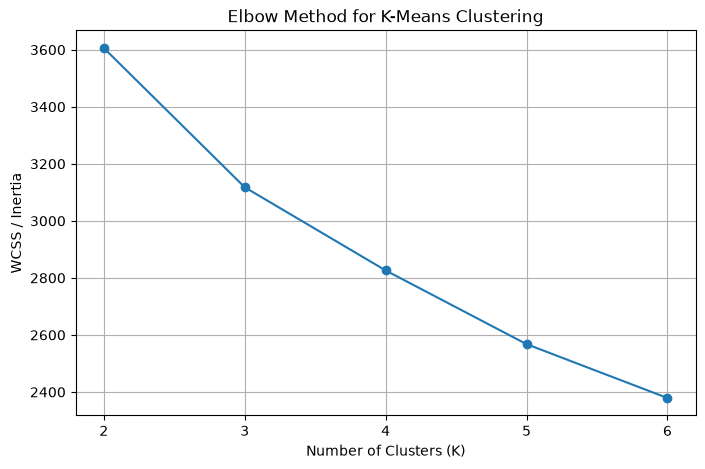

In [45]:
# ============================================================
# ELBOW METHOD - WCSS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["WCSS"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(results_df["K"])
plt.grid(True)

plt.show()

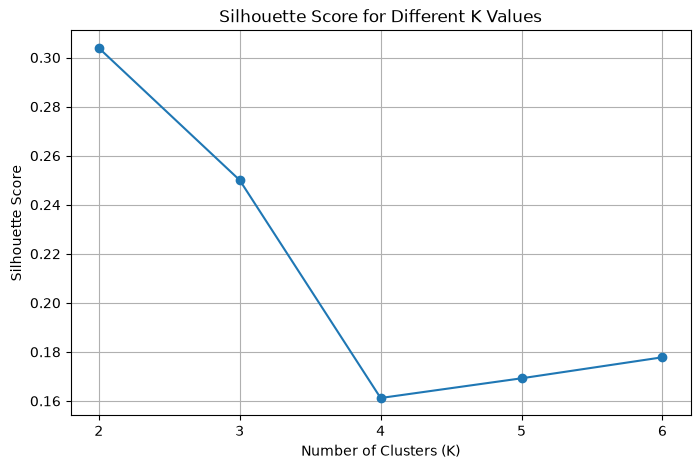

In [46]:
# ============================================================
# SILHOUETTE SCORE COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")
plt.xticks(results_df["K"])
plt.grid(True)

plt.show()

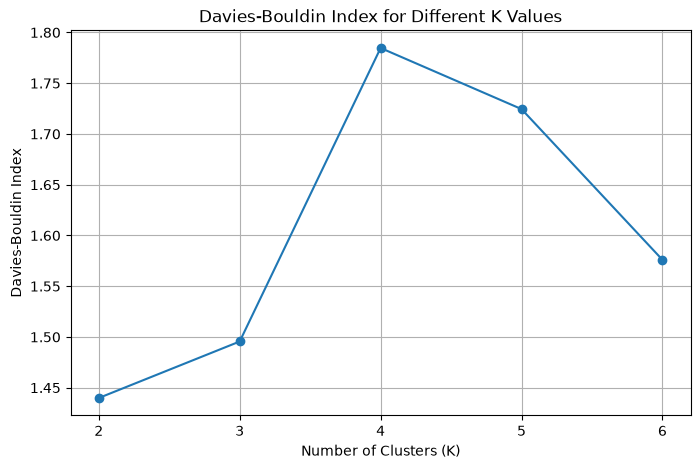

In [47]:
# ============================================================
# DAVIES-BOULDIN INDEX COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Davies-Bouldin Index"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index for Different K Values")
plt.xticks(results_df["K"])
plt.grid(True)

plt.show()

In [48]:
# ============================================================
# FINAL K-MEANS MODEL
# ============================================================

final_k = 2

final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

# Train the final model and assign each district to a cluster
final_labels = final_kmeans.fit_predict(X_scaled_df)

# Add cluster labels to the district dataset
district_results = district_features_imputed.copy()

district_results["Cluster"] = final_labels

print("Final K-Means model trained successfully!")
print("Number of clusters:", final_k)

print("\nCluster sizes:")
print(district_results["Cluster"].value_counts().sort_index())

Final K-Means model trained successfully!
Number of clusters: 2

Cluster sizes:
Cluster
0    236
1    105
Name: count, dtype: int64


In [49]:
district_results = district_features_imputed.copy()

In [50]:
# ============================================================
# CLUSTER PROFILES
# ============================================================

cluster_profiles = district_results.groupby("Cluster").mean(numeric_only=True)

print("Cluster profiles:")
display(cluster_profiles.round(2))

KeyError: 'Cluster'

In [51]:
# ============================================================
# DIFFERENCE BETWEEN CLUSTERS
# ============================================================

cluster_difference = (
    cluster_profiles.loc[1] - cluster_profiles.loc[0]
).sort_values(ascending=False)

print("Difference between Cluster 1 and Cluster 0:")
display(cluster_difference.round(2))

NameError: name 'cluster_profiles' is not defined

In [52]:
district_results = district_features_imputed.copy()
district_results["Cluster"] = final_labels

In [53]:
district_results = district_features_imputed.copy()

In [54]:
# ============================================================
# RESTORE CLUSTER LABELS
# ============================================================

district_results = district_features_imputed.copy()

district_results["Cluster"] = final_labels

print("Cluster column restored successfully!")
print("\nCluster sizes:")
print(district_results["Cluster"].value_counts().sort_index())

Cluster column restored successfully!

Cluster sizes:
Cluster
0    236
1    105
Name: count, dtype: int64


In [55]:
# ============================================================
# CLUSTER PROFILES
# ============================================================

cluster_profiles = district_results.groupby("Cluster").mean(numeric_only=True)

print("Cluster profiles:")
display(cluster_profiles.round(2))

Cluster profiles:


,12. Households with any usual member covered under a health insurance/financing scheme (%),30. Health worker ever talked to female non-users about family planning (%),32. Mothers who had an antenatal check-up in the first trimester (%),33. Mothers who had at least 4 antenatal care visits (%),34. Mothers whose last birth was protected against neonatal tetanus9 (%),35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),42. Institutional births (%),43. Institutional births in public facility (%),45. Births attended by skilled health personnel10 (%),53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%),8. Population living in households with an improved drinking-water source1 (%),9. Population living in households that use an improved sanitation facility2 (%)
Cluster,,,,,,,,,,,,,,,
0,39.76,23.59,78.97,73.48,92.14,56.30,85.09,94.90,62.73,94.19,90.54,91.01,78.32,95.22,76.33
1,29.97,18.71,57.09,38.55,87.47,28.18,58.58,73.38,58.63,77.27,79.79,80.65,56.46,87.23,64.70


In [56]:
# ============================================================
# DIFFERENCE BETWEEN CLUSTERS
# ============================================================

cluster_difference = (
    cluster_profiles.loc[1] - cluster_profiles.loc[0]
).sort_values(ascending=False)

print("Difference between Cluster 1 and Cluster 0:")
display(cluster_difference.round(2))

Difference between Cluster 1 and Cluster 0:


43. Institutional births in public facility (%)                                                                                     -4.10
34. Mothers whose last birth was protected against neonatal tetanus9 (%)                                                            -4.66
30. Health worker ever talked to female non-users about family planning (%)                                                         -4.88
8. Population living in households with an improved drinking-water source1 (%)                                                      -8.00
12. Households with any usual member covered under a health insurance/financing scheme (%)                                          -9.79
54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)                             -10.36
53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)                                                -10.75
9. Population living in households

In [57]:
# ============================================================
# COMPLETE CLUSTER COMPARISON
# ============================================================

cluster_comparison = pd.DataFrame({
    "Cluster_0_Mean": cluster_profiles.loc[0],
    "Cluster_1_Mean": cluster_profiles.loc[1],
    "Difference": cluster_profiles.loc[1] - cluster_profiles.loc[0]
})

cluster_comparison["Higher_Cluster"] = cluster_comparison.apply(
    lambda row: "Cluster 1" if row["Difference"] > 0 else "Cluster 0",
    axis=1
)

print("Complete Cluster Comparison:")
display(cluster_comparison.round(2))

Complete Cluster Comparison:


,Cluster_0_Mean,Cluster_1_Mean,Difference,Higher_Cluster
12. Households with any usual member covered under a health insurance/financing scheme (%),39.76,29.97,-9.79,Cluster 0
30. Health worker ever talked to female non-users about family planning (%),23.59,18.71,-4.88,Cluster 0
32. Mothers who had an antenatal check-up in the first trimester (%),78.97,57.09,-21.89,Cluster 0
33. Mothers who had at least 4 antenatal care visits (%),73.48,38.55,-34.93,Cluster 0
34. Mothers whose last birth was protected against neonatal tetanus9 (%),92.14,87.47,-4.66,Cluster 0
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),56.30,28.18,-28.12,Cluster 0
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),85.09,58.58,-26.51,Cluster 0
42. Institutional births (%),94.90,73.38,-21.52,Cluster 0
43. Institutional births in public facility (%),62.73,58.63,-4.10,Cluster 0
45. Births attended by skilled health personnel10 (%),94.19,77.27,-16.92,Cluster 0


In [58]:
# ============================================================
# DISTRICTS IN EACH CLUSTER
# ============================================================

cluster_0_districts = district_results[
    district_results["Cluster"] == 0
].copy()

cluster_1_districts = district_results[
    district_results["Cluster"] == 1
].copy()

print("Cluster 0 - Higher Healthcare Coverage")
print("Number of districts:", len(cluster_0_districts))

display(
    cluster_0_districts[
        ["state_code", "state", "district", "Cluster"]
    ].sort_values(["state", "district"])
)

print("\n" + "="*70 + "\n")

print("Cluster 1 - Lower Healthcare Coverage")
print("Number of districts:", len(cluster_1_districts))

display(
    cluster_1_districts[
        ["state_code", "state", "district", "Cluster"]
    ].sort_values(["state", "district"])
)

Cluster 0 - Higher Healthcare Coverage
Number of districts: 236


KeyError: "['state_code', 'state', 'district'] not in index"

In [59]:
index=["state_code", "state", "district"]

In [60]:
cluster_0_districts[["state_code", "state", "district", "Cluster"]]

KeyError: "['state_code', 'state', 'district'] not in index"

In [61]:
# ============================================================
# PREPARE DISTRICT RESULTS FOR DISPLAY
# ============================================================

# Convert state_code, state and district from index to columns
district_results_display = district_results.reset_index()

print("Columns:")
print(district_results_display.columns.tolist())

# Cluster 0
cluster_0_districts = district_results_display[
    district_results_display["Cluster"] == 0
].copy()

# Cluster 1
cluster_1_districts = district_results_display[
    district_results_display["Cluster"] == 1
].copy()

print("\nCluster 0 - Higher Healthcare Coverage")
print("Number of districts:", len(cluster_0_districts))

display(
    cluster_0_districts[
        ["state_code", "state", "district", "Cluster"]
    ].sort_values(["state", "district"])
)

print("\n" + "="*70 + "\n")

print("Cluster 1 - Lower Healthcare Coverage")
print("Number of districts:", len(cluster_1_districts))

display(
    cluster_1_districts[
        ["state_code", "state", "district", "Cluster"]
    ].sort_values(["state", "district"])
)

Columns:
['state_code', 'state', 'district', '12. Households with any usual member covered under a health insurance/financing scheme (%)', '30. Health worker ever talked to female non-users about family planning (%)', '32. Mothers who had an antenatal check-up in the first trimester (%)', '33. Mothers who had at least 4 antenatal care visits (%)', '34. Mothers whose last birth was protected against neonatal tetanus9 (%)', '35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%)', '38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%)', '42. Institutional births (%)', '43. Institutional births in public facility (%)', '45. Births attended by skilled health personnel10 (%)', '53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%)', '54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%)', '58. Children ag

,state_code,state,district,Cluster
0,AN,Andaman and Nicobar Island,Nicobar,0
1,AN,Andaman and Nicobar Island,North & Middle Andaman,0
2,AN,Andaman and Nicobar Island,South Andaman,0
3,AP,Andhra Pradesh,Anantapur,0
4,AP,Andhra Pradesh,Chittoor,0
...,...,...,...,...
335,WB,West Bengal,Paschim Medinipur,0
336,WB,West Bengal,Purba Barddhaman,0
337,WB,West Bengal,Purba Medinipur,0
339,WB,West Bengal,South Twenty Four Parganas,0




Cluster 1 - Lower Healthcare Coverage
Number of districts: 105


,state_code,state,district,Cluster
17,AS,Assam,Barpeta,1
18,AS,Assam,Biswanath,1
19,AS,Assam,Bongaigaon,1
20,AS,Assam,Cachar,1
23,AS,Assam,Darrang,1
...,...,...,...,...
315,TR,Tripura,Khowai,1
316,TR,Tripura,North Tripura,1
318,TR,Tripura,South Tripura,1
319,TR,Tripura,Unakoti,1


In [62]:
district_results_display = district_results.reset_index()

In [63]:
district_results_display

,state_code,state,district,12. Households with any usual member covered under a health insurance/financing scheme (%),30. Health worker ever talked to female non-users about family planning (%),32. Mothers who had an antenatal check-up in the first trimester (%),33. Mothers who had at least 4 antenatal care visits (%),34. Mothers whose last birth was protected against neonatal tetanus9 (%),35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),42. Institutional births (%),43. Institutional births in public facility (%),45. Births attended by skilled health personnel10 (%),53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%),8. Population living in households with an improved drinking-water source1 (%),9. Population living in households that use an improved sanitation facility2 (%),Cluster
0,AN,Andaman and Nicobar Island,Nicobar,2.7,40.4,62.8,71.7,78.0,72.6,85.1,97.8,96.7,98.6,71.9,67.3,94.9,98.8,83.5,0
1,AN,Andaman and Nicobar Island,North & Middle Andaman,2.1,23.2,74.5,79.2,91.1,83.7,92.5,97.7,95.0,98.3,89.0,89.4,89.6,92.2,86.4,0
2,AN,Andaman and Nicobar Island,South Andaman,1.2,31.2,79.4,85.9,92.1,81.0,88.1,99.5,83.8,96.9,94.8,81.7,84.0,97.9,89.3,0
3,AP,Andhra Pradesh,Anantapur,73.2,21.9,80.3,66.6,97.5,72.0,89.1,94.7,60.3,98.3,90.2,92.9,75.7,98.8,71.3,0
4,AP,Andhra Pradesh,Chittoor,70.7,21.3,80.3,65.3,97.8,71.7,93.8,97.1,66.5,97.6,88.4,89.6,76.9,98.5,74.6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
336,WB,West Bengal,Purba Barddhaman,37.2,16.0,72.5,80.5,90.8,68.3,65.2,96.0,70.3,94.3,100.0,100.0,65.2,99.1,64.2,0
337,WB,West Bengal,Purba Medinipur,21.5,20.6,69.3,56.8,87.1,51.6,48.5,91.5,71.5,94.6,91.7,91.7,83.7,87.8,69.8,0
338,WB,West Bengal,Puruliya,35.6,21.2,59.1,57.8,91.2,53.4,51.5,89.8,82.7,91.4,91.6,93.2,68.0,87.6,29.2,1
339,WB,West Bengal,South Twenty Four Parganas,36.7,17.7,77.1,87.5,96.4,67.2,67.0,91.0,77.7,93.2,94.9,94.8,58.8,100.0,70.1,0


In [64]:
# ============================================================
# STATE-WISE CLUSTER DISTRIBUTION
# ============================================================

state_cluster_distribution = pd.crosstab(
    district_results_display["state"],
    district_results_display["Cluster"]
)

# Rename cluster columns
state_cluster_distribution = state_cluster_distribution.rename(
    columns={
        0: "Higher_Healthcare_Coverage",
        1: "Lower_Healthcare_Coverage"
    }
)

# Add total districts
state_cluster_distribution["Total_Districts"] = (
    state_cluster_distribution["Higher_Healthcare_Coverage"] +
    state_cluster_distribution["Lower_Healthcare_Coverage"]
)

# Calculate percentage of districts in lower-coverage cluster
state_cluster_distribution["Lower_Coverage_Percentage"] = (
    state_cluster_distribution["Lower_Healthcare_Coverage"] /
    state_cluster_distribution["Total_Districts"] * 100
)

# Sort by percentage of lower-coverage districts
state_cluster_distribution = state_cluster_distribution.sort_values(
    "Lower_Coverage_Percentage",
    ascending=False
)

print("State-wise Cluster Distribution:")
display(state_cluster_distribution.round(2))

State-wise Cluster Distribution:


Cluster,Higher_Healthcare_Coverage,Lower_Healthcare_Coverage,Total_Districts,Lower_Coverage_Percentage
state,,,,
Nagaland,0,11,11,100.00
Bihar,1,37,38,97.37
Meghalaya,1,10,11,90.91
Tripura,2,6,8,75.00
Manipur,3,6,9,66.67
Assam,15,18,33,54.55
Maharashtra,27,9,36,25.00
Mizoram,6,2,8,25.00
Jammu and Kashmir,17,3,20,15.00


In [65]:
# ============================================================
# STATES WITH HIGHEST HIGHER-COVERAGE CONCENTRATION
# ============================================================

state_cluster_distribution["Higher_Coverage_Percentage"] = (
    state_cluster_distribution["Higher_Healthcare_Coverage"] /
    state_cluster_distribution["Total_Districts"] * 100
)

print("Top states by percentage of higher-coverage districts:")

display(
    state_cluster_distribution[
        [
            "Higher_Healthcare_Coverage",
            "Lower_Healthcare_Coverage",
            "Total_Districts",
            "Higher_Coverage_Percentage"
        ]
    ].sort_values(
        "Higher_Coverage_Percentage",
        ascending=False
    ).head(10).round(2)
)

Top states by percentage of higher-coverage districts:


Cluster,Higher_Healthcare_Coverage,Lower_Healthcare_Coverage,Total_Districts,Higher_Coverage_Percentage
state,,,,
Himachal Pradesh,12,0,12,100.00
Ladakh,2,0,2,100.00
Kerala,14,0,14,100.00
Telangana,31,0,31,100.00
Andaman and Nicobar Island,3,0,3,100.00
Sikkim,4,0,4,100.00
Goa,2,0,2,100.00
Andhra Pradesh,13,0,13,100.00
Dadra & Nagar Haveli and Daman & Diu,3,0,3,100.00


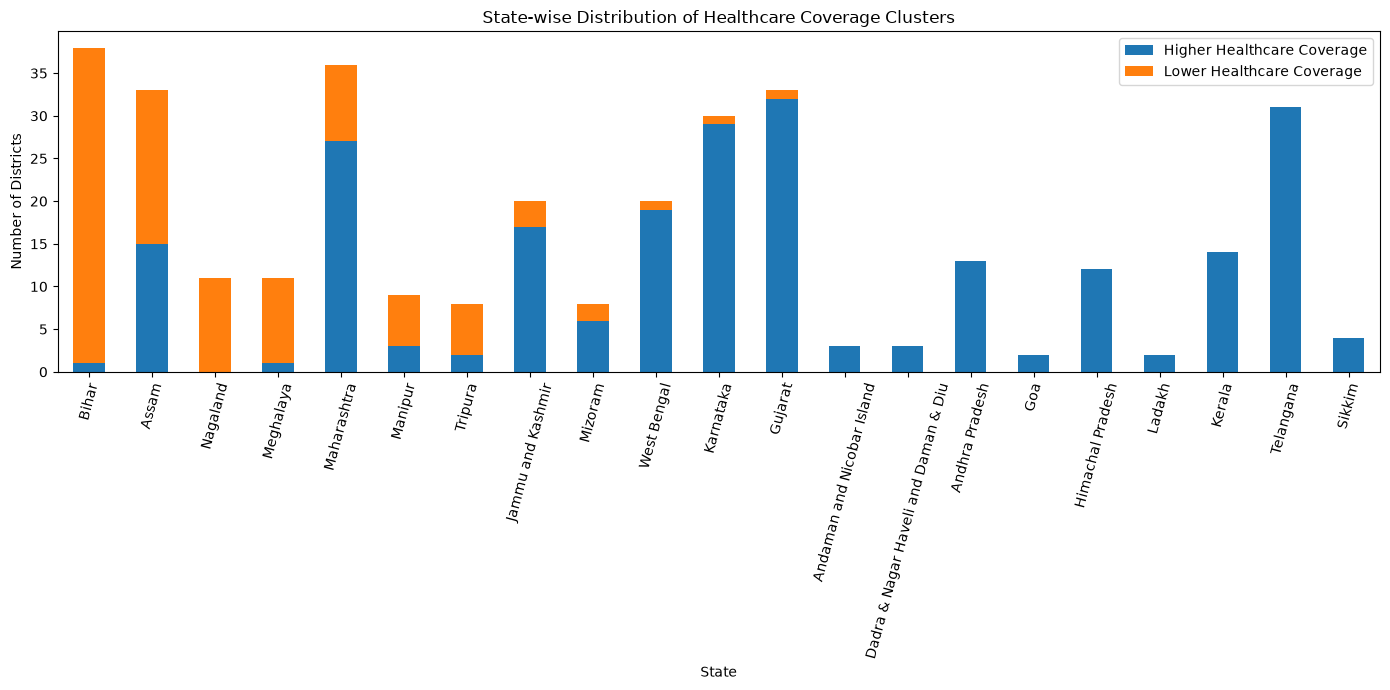

In [66]:
# ============================================================
# STATE-WISE CLUSTER DISTRIBUTION - STACKED BAR CHART
# ============================================================

import matplotlib.pyplot as plt

plot_data = state_cluster_distribution[
    ["Higher_Healthcare_Coverage", "Lower_Healthcare_Coverage"]
].sort_values(
    "Lower_Healthcare_Coverage",
    ascending=False
)

plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.xlabel("State")
plt.ylabel("Number of Districts")
plt.title("State-wise Distribution of Healthcare Coverage Clusters")
plt.xticks(rotation=75)
plt.legend(
    ["Higher Healthcare Coverage", "Lower Healthcare Coverage"]
)
plt.tight_layout()
plt.show()

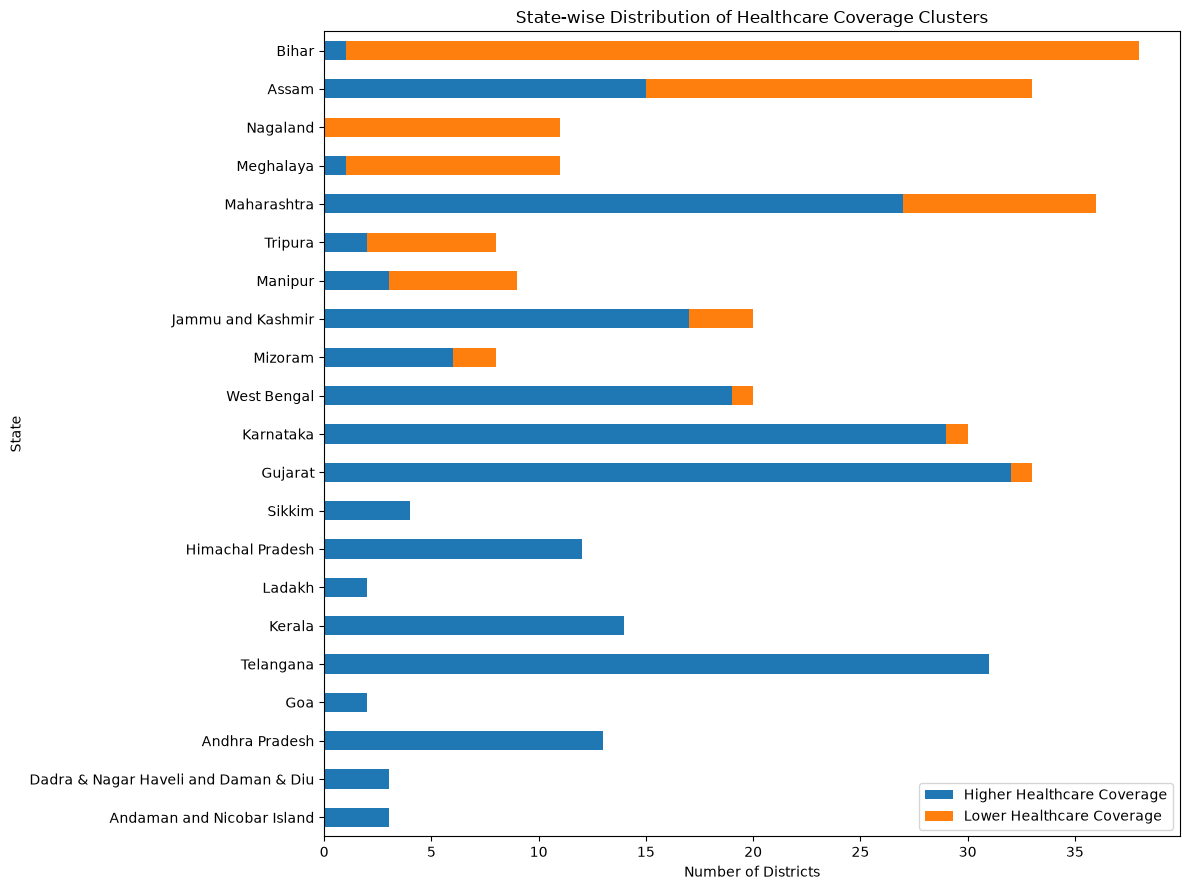

In [67]:
# ============================================================
# HORIZONTAL STATE-WISE CLUSTER DISTRIBUTION
# ============================================================

plot_data = state_cluster_distribution[
    ["Higher_Healthcare_Coverage", "Lower_Healthcare_Coverage"]
].sort_values(
    "Lower_Healthcare_Coverage",
    ascending=True
)

plot_data.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 9)
)

plt.xlabel("Number of Districts")
plt.ylabel("State")
plt.title("State-wise Distribution of Healthcare Coverage Clusters")

plt.legend(
    ["Higher Healthcare Coverage", "Lower Healthcare Coverage"],
    loc="lower right"
)

plt.tight_layout()
plt.show()

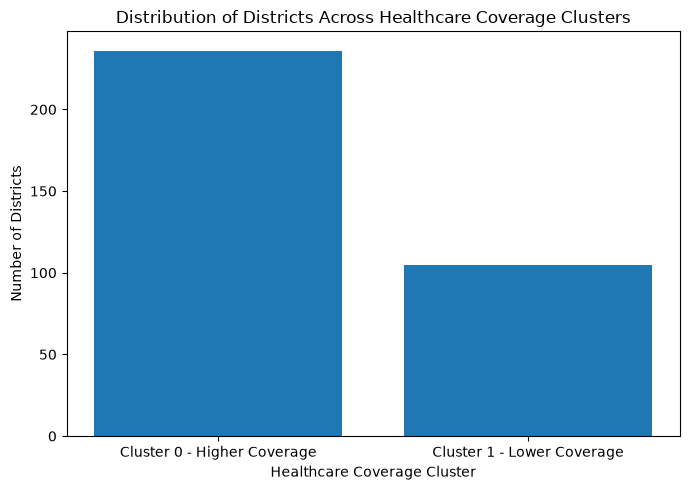

In [68]:
# ============================================================
# CLUSTER SIZE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

cluster_counts = district_results["Cluster"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Cluster 0 - Higher Coverage", "Cluster 1 - Lower Coverage"],
    cluster_counts.values
)

plt.xlabel("Healthcare Coverage Cluster")
plt.ylabel("Number of Districts")
plt.title("Distribution of Districts Across Healthcare Coverage Clusters")

plt.tight_layout()
plt.show()

In [69]:
# ============================================================
# CLUSTER PERCENTAGES
# ============================================================

total_districts = len(district_results)

cluster_summary = pd.DataFrame({
    "Cluster": [0, 1],
    "Coverage_Level": [
        "Higher Healthcare Coverage",
        "Lower Healthcare Coverage"
    ],
    "District_Count": [
        cluster_counts.get(0, 0),
        cluster_counts.get(1, 0)
    ]
})

cluster_summary["Percentage"] = (
    cluster_summary["District_Count"] / total_districts * 100
)

display(cluster_summary.round(2))

,Cluster,Coverage_Level,District_Count,Percentage
0,0,Higher Healthcare Coverage,236,69.21
1,1,Lower Healthcare Coverage,105,30.79


In [70]:
# ============================================================
# PCA VISUALIZATION OF K-MEANS CLUSTERS
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled_df)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": final_labels
})

print("Explained variance ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

print(
    "Total variance explained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

display(pca_df.head())

Explained variance ratio:
PC1: 0.4294
PC2: 0.1336
Total variance explained: 0.563


,PC1,PC2,Cluster
0,0.249664,0.752167,0
1,2.199732,-0.406342,0
2,2.290420,-0.118247,0
3,2.036829,0.634362,0
4,2.060063,0.721021,0


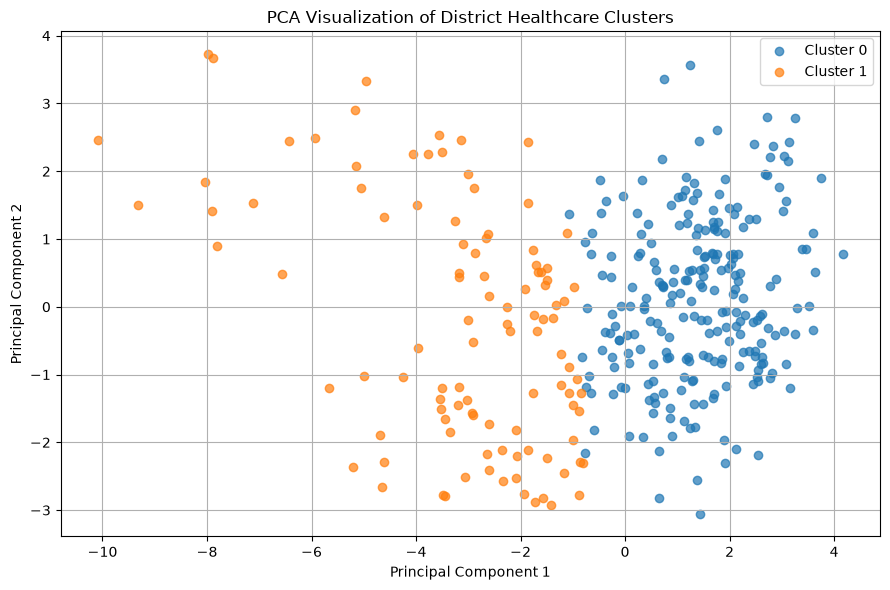

In [71]:
# ============================================================
# PCA CLUSTER PLOT
# ============================================================

plt.figure(figsize=(9, 6))

for cluster in sorted(pca_df["Cluster"].unique()):

    cluster_data = pca_df[pca_df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of District Healthcare Clusters")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [72]:
# ============================================================
# LOWER-COVERAGE DISTRICTS
# ============================================================

lower_coverage_districts = district_results_display[
    district_results_display["Cluster"] == 1
].copy()

print("Total lower-coverage districts:",
      len(lower_coverage_districts))

display(
    lower_coverage_districts[
        ["state_code", "state", "district", "Cluster"]
    ].sort_values(
        ["state", "district"]
    )
)

Total lower-coverage districts: 105


,state_code,state,district,Cluster
17,AS,Assam,Barpeta,1
18,AS,Assam,Biswanath,1
19,AS,Assam,Bongaigaon,1
20,AS,Assam,Cachar,1
23,AS,Assam,Darrang,1
...,...,...,...,...
315,TR,Tripura,Khowai,1
316,TR,Tripura,North Tripura,1
318,TR,Tripura,South Tripura,1
319,TR,Tripura,Unakoti,1


In [73]:
# ============================================================
# TOP STATES WITH LOWER-COVERAGE DISTRICTS
# ============================================================

top_lower_states = (
    state_cluster_distribution
    .sort_values(
        "Lower_Healthcare_Coverage",
        ascending=False
    )
    [["Lower_Healthcare_Coverage",
      "Higher_Healthcare_Coverage",
      "Total_Districts",
      "Lower_Coverage_Percentage"]]
    .head(10)
)

display(top_lower_states.round(2))

Cluster,Lower_Healthcare_Coverage,Higher_Healthcare_Coverage,Total_Districts,Lower_Coverage_Percentage
state,,,,
Bihar,37,1,38,97.37
Assam,18,15,33,54.55
Nagaland,11,0,11,100.00
Meghalaya,10,1,11,90.91
Maharashtra,9,27,36,25.00
Manipur,6,3,9,66.67
Tripura,6,2,8,75.00
Jammu and Kashmir,3,17,20,15.00
Mizoram,2,6,8,25.00


In [74]:
# ============================================================
# SAVE FINAL CLUSTERED DATASET
# ============================================================

district_results_display.to_csv(
    "final_district_healthcare_clusters.csv",
    index=False
)

print("Final clustered dataset saved successfully.")
print("Shape:", district_results_display.shape)

Final clustered dataset saved successfully.
Shape: (341, 19)


In [75]:
# ============================================================
# TOP INDICATORS SEPARATING THE TWO CLUSTERS
# ============================================================

cluster_difference = (
    cluster_profiles.loc[1] - cluster_profiles.loc[0]
).sort_values()

indicator_comparison = pd.DataFrame({
    "Cluster_0_Mean": cluster_profiles.loc[0],
    "Cluster_1_Mean": cluster_profiles.loc[1],
    "Difference": cluster_difference
})

indicator_comparison["Absolute_Difference"] = (
    indicator_comparison["Difference"].abs()
)

indicator_comparison["Higher_Cluster"] = indicator_comparison[
    "Difference"
].apply(
    lambda x: "Cluster 1" if x > 0 else "Cluster 0"
)

indicator_comparison = indicator_comparison.sort_values(
    "Absolute_Difference",
    ascending=False
)

print("Top indicators separating the clusters:")
display(
    indicator_comparison[
        [
            "Cluster_0_Mean",
            "Cluster_1_Mean",
            "Difference",
            "Higher_Cluster"
        ]
    ].round(2)
)

Top indicators separating the clusters:


,Cluster_0_Mean,Cluster_1_Mean,Difference,Higher_Cluster
33. Mothers who had at least 4 antenatal care visits (%),73.48,38.55,-34.93,Cluster 0
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),56.30,28.18,-28.12,Cluster 0
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),85.09,58.58,-26.51,Cluster 0
32. Mothers who had an antenatal check-up in the first trimester (%),78.97,57.09,-21.89,Cluster 0
58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%),78.32,56.46,-21.86,Cluster 0
42. Institutional births (%),94.90,73.38,-21.52,Cluster 0
45. Births attended by skilled health personnel10 (%),94.19,77.27,-16.92,Cluster 0
9. Population living in households that use an improved sanitation facility2 (%),76.33,64.70,-11.63,Cluster 0
53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),90.54,79.79,-10.75,Cluster 0
54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),91.01,80.65,-10.36,Cluster 0


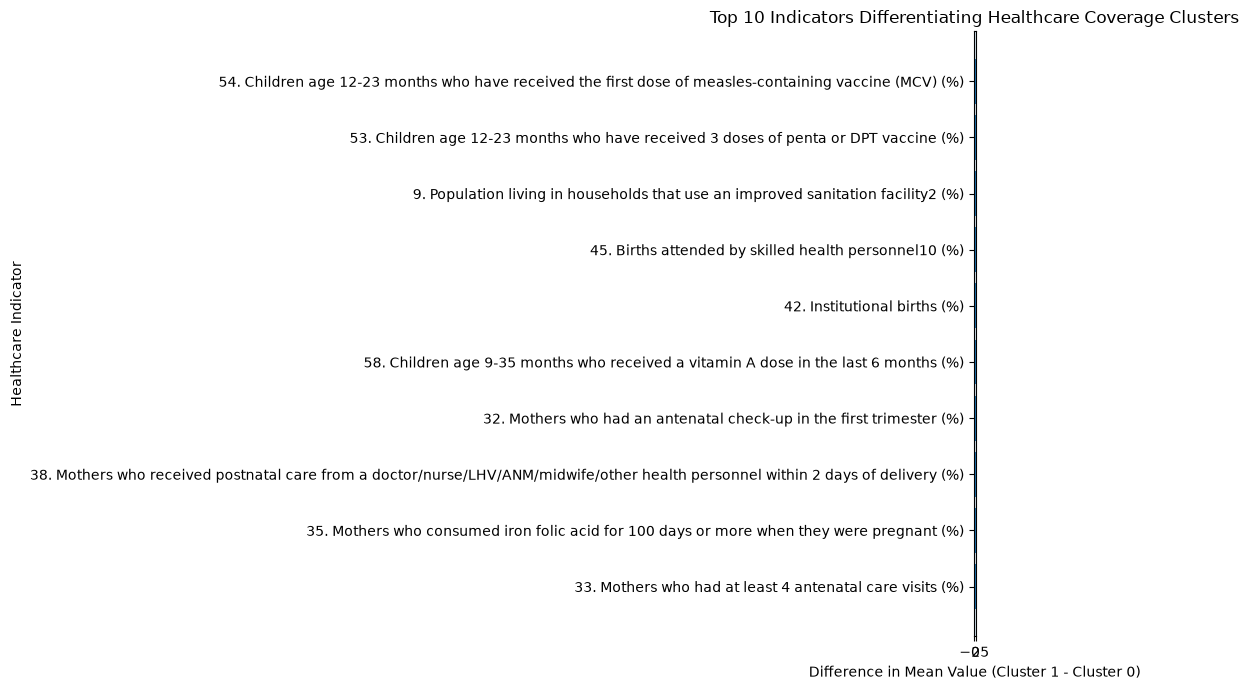

In [76]:
# ============================================================
# TOP 10 INDICATORS BY CLUSTER DIFFERENCE
# ============================================================

top_10 = indicator_comparison.head(10).sort_values(
    "Difference"
)

plt.figure(figsize=(10, 7))

plt.barh(
    range(len(top_10)),
    top_10["Difference"]
)

plt.yticks(
    range(len(top_10)),
    top_10.index
)

plt.axvline(0, linewidth=1)

plt.xlabel("Difference in Mean Value (Cluster 1 - Cluster 0)")
plt.ylabel("Healthcare Indicator")
plt.title("Top 10 Indicators Differentiating Healthcare Coverage Clusters")

plt.tight_layout()
plt.show()

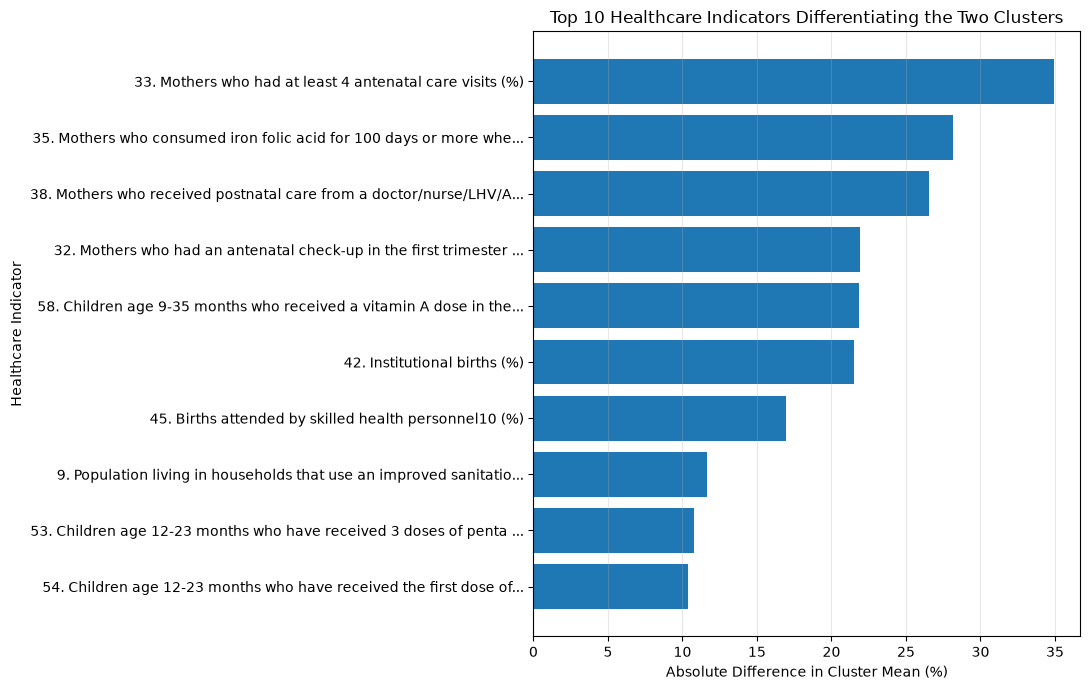

In [77]:
# ============================================================
# TOP 10 INDICATORS BY DIFFERENCE BETWEEN CLUSTERS
# ============================================================

top_10 = indicator_comparison.head(10).copy()

# Use absolute difference for easier visualization
top_10["Difference_Absolute"] = top_10["Difference"].abs()

top_10 = top_10.sort_values(
    "Difference_Absolute",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    range(len(top_10)),
    top_10["Difference_Absolute"]
)

plt.yticks(
    range(len(top_10)),
    [
        indicator[:65] + "..." if len(indicator) > 65 else indicator
        for indicator in top_10.index
    ]
)

plt.xlabel("Absolute Difference in Cluster Mean (%)")
plt.ylabel("Healthcare Indicator")

plt.title(
    "Top 10 Healthcare Indicators Differentiating the Two Clusters"
)

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# FINAL PROJECT RESULTS SUMMARY
# ============================================================

print("=" * 70)
print("DISTRICT HEALTHCARE SEGMENTATION - FINAL RESULTS")
print("=" * 70)

print("\nDataset:")
print("Total districts:", len(district_results))
print("Total selected indicators:", len(X_scaled_df.columns))

print("\nClustering:")
print("Algorithm: K-Means")
print("Optimal K:", final_k)

print("\nCluster Distribution:")

for cluster in sorted(cluster_counts.index):
    count = cluster_counts[cluster]
    percentage = (count / total_districts) * 100

    if cluster == 0:
        label = "Higher Healthcare Coverage"
    else:
        label = "Lower Healthcare Coverage"

    print(
        f"Cluster {cluster} - {label}: "
        f"{count} districts ({percentage:.2f}%)"
    )

print("\nPCA:")
print(
    "PC1 variance explained:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)

print(
    "PC2 variance explained:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)

print(
    "PC1 + PC2 variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("\nTop 5 indicators separating the clusters:")

display(
    indicator_comparison[
        [
            "Cluster_0_Mean",
            "Cluster_1_Mean",
            "Difference",
            "Higher_Cluster"
        ]
    ].head(5).round(2)
)

DISTRICT HEALTHCARE SEGMENTATION - FINAL RESULTS

Dataset:
Total districts: 341
Total selected indicators: 15

Clustering:
Algorithm: K-Means
Optimal K: 2

Cluster Distribution:
Cluster 0 - Higher Healthcare Coverage: 236 districts (69.21%)
Cluster 1 - Lower Healthcare Coverage: 105 districts (30.79%)

PCA:
PC1 variance explained: 42.94 %
PC2 variance explained: 13.36 %
PC1 + PC2 variance explained: 56.3 %

Top 5 indicators separating the clusters:


,Cluster_0_Mean,Cluster_1_Mean,Difference,Higher_Cluster
33. Mothers who had at least 4 antenatal care visits (%),73.48,38.55,-34.93,Cluster 0
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),56.30,28.18,-28.12,Cluster 0
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),85.09,58.58,-26.51,Cluster 0
32. Mothers who had an antenatal check-up in the first trimester (%),78.97,57.09,-21.89,Cluster 0
58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%),78.32,56.46,-21.86,Cluster 0


In [79]:
# ============================================================
# SAVE ANALYSIS RESULTS
# ============================================================

cluster_summary.to_csv(
    "cluster_summary.csv",
    index=False
)

indicator_comparison.to_csv(
    "indicator_cluster_comparison.csv"
)

state_cluster_distribution.to_csv(
    "state_cluster_distribution.csv"
)

pca_df.to_csv(
    "pca_coordinates.csv",
    index=False
)

print("All analysis results saved successfully.")

All analysis results saved successfully.


In [80]:
# ============================================================
# FINAL CLUSTER PROFILE TABLE
# ============================================================

final_cluster_profiles = cluster_profiles.T.copy()

final_cluster_profiles.columns = [
    "Cluster_0_Higher_Coverage",
    "Cluster_1_Lower_Coverage"
]

final_cluster_profiles["Difference"] = (
    final_cluster_profiles["Cluster_0_Higher_Coverage"]
    - final_cluster_profiles["Cluster_1_Lower_Coverage"]
)

final_cluster_profiles = final_cluster_profiles.sort_values(
    "Difference",
    ascending=False
)

print("Final Cluster Profiles:")
display(final_cluster_profiles.round(2))

Final Cluster Profiles:


,Cluster_0_Higher_Coverage,Cluster_1_Lower_Coverage,Difference
33. Mothers who had at least 4 antenatal care visits (%),73.48,38.55,34.93
35. Mothers who consumed iron folic acid for 100 days or more when they were pregnant (%),56.30,28.18,28.12
38. Mothers who received postnatal care from a doctor/nurse/LHV/ANM/midwife/other health personnel within 2 days of delivery (%),85.09,58.58,26.51
32. Mothers who had an antenatal check-up in the first trimester (%),78.97,57.09,21.89
58. Children age 9-35 months who received a vitamin A dose in the last 6 months (%),78.32,56.46,21.86
42. Institutional births (%),94.90,73.38,21.52
45. Births attended by skilled health personnel10 (%),94.19,77.27,16.92
9. Population living in households that use an improved sanitation facility2 (%),76.33,64.70,11.63
53. Children age 12-23 months who have received 3 doses of penta or DPT vaccine (%),90.54,79.79,10.75
54. Children age 12-23 months who have received the first dose of measles-containing vaccine (MCV) (%),91.01,80.65,10.36


In [81]:
# ============================================================
# KEY FINDINGS
# ============================================================

key_findings = pd.DataFrame({
    "Finding": [
        "Higher healthcare coverage cluster",
        "Lower healthcare coverage cluster",
        "Largest healthcare gap",
        "Second largest healthcare gap",
        "Third largest healthcare gap"
    ],
    
    "Result": [
        f"{cluster_counts[0]} districts ({cluster_counts[0]/total_districts*100:.2f}%)",
        f"{cluster_counts[1]} districts ({cluster_counts[1]/total_districts*100:.2f}%)",
        indicator_comparison.index[0],
        indicator_comparison.index[1],
        indicator_comparison.index[2]
    ]
})

display(key_findings)

,Finding,Result
0,Higher healthcare coverage cluster,236 districts (69.21%)
1,Lower healthcare coverage cluster,105 districts (30.79%)
2,Largest healthcare gap,33. Mothers who had at least 4 antenatal care ...
3,Second largest healthcare gap,35. Mothers who consumed iron folic acid for 1...
4,Third largest healthcare gap,38. Mothers who received postnatal care from a...


In [ ]:
StandardScaler()